# Import Libraries

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import os
import glob
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, cross_val_score,GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_classification
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV

warnings.filterwarnings('ignore')

# Reading Data

In [4]:
df=pd.read_csv("C:\\Users\\dpree\\Desktop\\Kolate.AI\\1186\\Data\\Regression_Dataset.csv")

In [5]:
df.columns

Index(['Unnamed: 0', 'SUBJID', 'AGE', 'SEXCD', 'TRTDOSE', 'ATRT', 'PRBEVCD',
       'PROXACDR', 'PROXAM', 'PFSCR', 'PFSCRV', 'PDLR', 'TRTDUR', 'B_METANM',
       'KRAS', 'TUMCAT', 'LIVRONLY', 'PFSCR.1', 'PDLR.1', 'B_ALPNM', 'B_CEA',
       'B_CREAT', 'CDOSE_x', 'IRCDOSE', 'FBDUR', 'FBCDOSE', 'FIDUR', 'FICDOSE',
       'DIAGMONS_x', 'METMONS', 'BIOPTPCT', 'BIOPRS', 'CDOSE_y', 'DSDLYPC',
       'CHDLYNM', 'CHDLYPC', 'PROPDOSE', 'CHRESPCD', 'CHDRSNCD', 'CHTERM_5 FU',
       'CHTERM_5-FU', 'CHTERM_CAPECITABINE', 'CHTERM_LEUCOVORIN',
       'CHTERM_OXALIPLATIN', 'CHANY_Y', 'DTCAUSCD', 'DIAGMONS_y', 'BIOPACPT',
       'BIOPCYTO', 'PFUP', 'KRASCD', 'EVALITT_Y', 'EXDURMN', 'ACTTRTCD',
       'DOSE', 'LBSTRESN', 'LBSTNRLO', 'LBSTNRHI', 'LBORRESN', 'LBBLRES',
       'LBBASE_N', 'LBBASE_Y', 'DOSREFDY', 'ENRREFDY', 'LSSLD', 'LSSLDPCH',
       'LSSLDPCN', 'LSRI', 'LSTYPE_Central', 'LSTYPE_Local', 'LSCAT',
       'LSNEWANY', 'LPSUM', 'OTANY_N', 'OTANY_Y', 'RAANY_N', 'RAANY_Y',
       'RSNEW_N', 'RSN

In [6]:
df.shape

(3089, 83)

In [7]:
df['Set'] = df['ATRT'].apply(lambda x: 'Control Arm' if x == 'FOLFIRI' else 'Treatment Arm')

In [8]:
df = df[df['LSNEWANY'] != '0']

In [9]:
df.head()

,Unnamed: 0,SUBJID,AGE,SEXCD,TRTDOSE,ATRT,PRBEVCD,PROXACDR,PROXAM,PFSCR,...,OTANY_Y,RAANY_N,RAANY_Y,RSNEW_N,RSNEW_Y,SXANY_N,SXANY_Y,VSNUMINF,VSSTRES,Set
0,0,201001001,54.0,M,6.0,Panitumumab + FOLFIRI,1.0,1.0,Y,1.0,...,1,1,0,1,1,0,1,7.52,58.039,Treatment Arm
1,1,201001001,54.0,M,6.0,Panitumumab + FOLFIRI,1.0,1.0,Y,1.0,...,1,1,0,1,1,0,1,7.52,58.039,Treatment Arm
2,2,201001001,54.0,M,6.0,Panitumumab + FOLFIRI,1.0,1.0,Y,1.0,...,1,1,0,1,1,0,1,7.52,58.039,Treatment Arm
3,3,201001001,54.0,M,6.0,Panitumumab + FOLFIRI,1.0,1.0,Y,1.0,...,1,1,0,1,1,0,1,7.52,58.039,Treatment Arm
4,4,201001001,54.0,M,6.0,Panitumumab + FOLFIRI,1.0,1.0,Y,1.0,...,1,1,0,1,1,0,1,7.52,58.039,Treatment Arm


In [10]:
df['LSNEWANY'].unique()

array(['N', 'Y'], dtype=object)

In [11]:
# 0 is LSNEWANY ='N' and 1 is 'LSNEWANY'='Y'

# Feature Selection by Random Forest

In [13]:
df1=df

In [14]:
df1['LSNEWANY'] = df1['LSNEWANY'].astype('category').cat.codes

In [15]:
df1 = pd.get_dummies(df1, drop_first=True)

In [16]:
# Separate features and target
X = df1.drop('LSNEWANY', axis=1)
y = df1['LSNEWANY']

In [17]:
# Train a Random Forest model
rf = RandomForestClassifier(random_state=42)
rf.fit(X, y)

RandomForestClassifier(random_state=42)

In [18]:
importances = rf.feature_importances_

In [19]:
# Create a dataframe for feature importances
feature_importances_df = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
feature_importances_df = feature_importances_df.sort_values(by='Importance', ascending=False)

In [20]:
feature_importances_df

,Feature,Importance
0,Unnamed: 0,0.338919
68,RSNEW_Y,0.090437
87,LSCAT_Target lesion,0.069354
86,LSCAT_Non-target lesion,0.067663
55,ENRREFDY,0.015744
...,...,...
67,RSNEW_N,0.000000
61,LSTYPE_Local,0.000000
60,LSTYPE_Central,0.000000
53,LBBASE_Y,0.000000


# Forming New Dataset

In [22]:
df=df[['SUBJID','LSNEWANY','DOSREFDY','LSSLD','LSCAT','LSSLDPCN','RSNEW_Y','ENRREFDY','B_ALPNM','LBSTRESN','B_CEA','LBORRESN','PFUP','LBSTNRHI',
       'EXDURMN','METMONS','DOSE','DIAGMONS_y','VSSTRES','LBSTNRLO','LBBLRES','B_CREAT','BIOPTPCT','FBCDOSE','FICDOSE','IRCDOSE','AGE','FBDUR','VSNUMINF',
       'FIDUR','TRTDUR','LSRI','CHDLYPC','DSDLYPC','B_METANM','PFSCR','Set']]
df.shape

(3085, 37)

In [23]:
df.head()

,SUBJID,LSNEWANY,DOSREFDY,LSSLD,LSCAT,LSSLDPCN,RSNEW_Y,ENRREFDY,B_ALPNM,LBSTRESN,...,FBDUR,VSNUMINF,FIDUR,TRTDUR,LSRI,CHDLYPC,DSDLYPC,B_METANM,PFSCR,Set
0,201001001,0,113.761468,105.581818,Target lesion,-1.491803,1,115.761468,106.0,53.119213,...,230.0,7.52,230.0,219.0,4.0,0.0625,0.0625,4.0,1.0,Treatment Arm
1,201001001,0,113.761468,105.581818,Non-target lesion,-1.491803,1,115.761468,106.0,53.119213,...,230.0,7.52,230.0,219.0,4.0,0.0625,0.0625,4.0,1.0,Treatment Arm
2,201001001,1,113.761468,105.581818,Target lesion,-1.491803,1,115.761468,106.0,53.119213,...,230.0,7.52,230.0,219.0,4.0,0.0625,0.0625,4.0,1.0,Treatment Arm
3,201001001,1,113.761468,105.581818,Non-target lesion,-1.491803,1,115.761468,106.0,53.119213,...,230.0,7.52,230.0,219.0,4.0,0.0625,0.0625,4.0,1.0,Treatment Arm
4,201001001,1,113.761468,105.581818,New lesion,-1.491803,1,115.761468,106.0,53.119213,...,230.0,7.52,230.0,219.0,4.0,0.0625,0.0625,4.0,1.0,Treatment Arm


# New Lesion Dataset

In [25]:
dfnew=df[['SUBJID','LSNEWANY','DOSREFDY','LSSLD','LSSLDPCN','RSNEW_Y','ENRREFDY','B_ALPNM','LBSTRESN','B_CEA','LBORRESN','PFUP','LBSTNRHI',
       'EXDURMN','METMONS','DOSE','DIAGMONS_y','VSSTRES','LBSTNRLO','LBBLRES','B_CREAT','BIOPTPCT','FBCDOSE','FICDOSE','IRCDOSE','AGE','FBDUR','VSNUMINF',
       'FIDUR','TRTDUR','LSRI','CHDLYPC','DSDLYPC','B_METANM','PFSCR']]

In [26]:
dfnew=dfnew.drop_duplicates(keep='first')
dfnew.shape

(1364, 35)

In [27]:
dfnew.head()

,SUBJID,LSNEWANY,DOSREFDY,LSSLD,LSSLDPCN,RSNEW_Y,ENRREFDY,B_ALPNM,LBSTRESN,B_CEA,...,AGE,FBDUR,VSNUMINF,FIDUR,TRTDUR,LSRI,CHDLYPC,DSDLYPC,B_METANM,PFSCR
0,201001001,0,113.761468,105.581818,-1.491803,1,115.761468,106.0,53.119213,17.5,...,54.0,230.0,7.520000,230.0,219.0,4.0,0.062500,0.062500,4.0,1.0
2,201001001,1,113.761468,105.581818,-1.491803,1,115.761468,106.0,53.119213,17.5,...,54.0,230.0,7.520000,230.0,219.0,4.0,0.062500,0.062500,4.0,1.0
5,201001002,0,25.050000,195.653846,27.785714,1,31.050000,173.0,64.343600,18.1,...,66.0,71.0,2.150000,71.0,60.0,4.0,0.000000,0.000000,3.0,1.0
7,201001002,1,25.050000,195.653846,27.785714,1,31.050000,173.0,64.343600,18.1,...,66.0,71.0,2.150000,71.0,60.0,4.0,0.000000,0.000000,3.0,1.0
10,201001004,0,224.111111,72.343434,-6.839286,0,229.111111,175.0,49.464788,252.6,...,58.0,448.0,13.037267,448.0,437.0,4.0,0.259259,0.259259,3.0,1.0


In [28]:
dfnew['study_month'] = pd.cut(dfnew['DOSREFDY'], [dfnew['DOSREFDY'].min(),0,31,61,91,121,151,181,210,dfnew['DOSREFDY'].max()],labels = ['before_study','month1','month2','month3','month4','month5','month6','month7','>month7'])

In [29]:
dfnew.to_csv("C:\\Users\\dpree\\Desktop\\Kolate.AI\\1186\\Data\\New_Lesion_Dataset.csv")

In [30]:
dfnew=pd.read_csv("C:\\Users\\dpree\\Desktop\\Kolate.AI\\1186\\Data\\New_Lesion_Dataset.csv")

In [31]:
dfnew.head()

,Unnamed: 0,SUBJID,LSNEWANY,DOSREFDY,LSSLD,LSSLDPCN,RSNEW_Y,ENRREFDY,B_ALPNM,LBSTRESN,...,FBDUR,VSNUMINF,FIDUR,TRTDUR,LSRI,CHDLYPC,DSDLYPC,B_METANM,PFSCR,study_month
0,0,201001001,0,113.761468,105.581818,-1.491803,1,115.761468,106.0,53.119213,...,230.0,7.520000,230.0,219.0,4.0,0.062500,0.062500,4.0,1.0,month4
1,2,201001001,1,113.761468,105.581818,-1.491803,1,115.761468,106.0,53.119213,...,230.0,7.520000,230.0,219.0,4.0,0.062500,0.062500,4.0,1.0,month4
2,5,201001002,0,25.050000,195.653846,27.785714,1,31.050000,173.0,64.343600,...,71.0,2.150000,71.0,60.0,4.0,0.000000,0.000000,3.0,1.0,month1
3,7,201001002,1,25.050000,195.653846,27.785714,1,31.050000,173.0,64.343600,...,71.0,2.150000,71.0,60.0,4.0,0.000000,0.000000,3.0,1.0,month1
4,10,201001004,0,224.111111,72.343434,-6.839286,0,229.111111,175.0,49.464788,...,448.0,13.037267,448.0,437.0,4.0,0.259259,0.259259,3.0,1.0,>month7


In [32]:
dfnew.columns

Index(['Unnamed: 0', 'SUBJID', 'LSNEWANY', 'DOSREFDY', 'LSSLD', 'LSSLDPCN',
       'RSNEW_Y', 'ENRREFDY', 'B_ALPNM', 'LBSTRESN', 'B_CEA', 'LBORRESN',
       'PFUP', 'LBSTNRHI', 'EXDURMN', 'METMONS', 'DOSE', 'DIAGMONS_y',
       'VSSTRES', 'LBSTNRLO', 'LBBLRES', 'B_CREAT', 'BIOPTPCT', 'FBCDOSE',
       'FICDOSE', 'IRCDOSE', 'AGE', 'FBDUR', 'VSNUMINF', 'FIDUR', 'TRTDUR',
       'LSRI', 'CHDLYPC', 'DSDLYPC', 'B_METANM', 'PFSCR', 'study_month'],
      dtype='object')

In [33]:
dataset_month1 = dfnew[dfnew['study_month'] == 'month1']
dataset_month2 = dfnew[dfnew['study_month'] == 'month2']
dataset_other = dfnew[(dfnew['study_month'] != 'month1') & (dfnew['study_month'] != 'month2')]

# Regression for New Lesions

# Month 1

In [36]:
result1=dataset_month1

In [37]:
result1.shape

(300, 37)

In [38]:
result1['LSNEWANY'] = result1['LSNEWANY'].astype('category').cat.codes

result1.isnull().sum()

In [40]:
result1.fillna(0, inplace=True)

In [41]:
X=result1[['DOSREFDY','LSSLD','LSSLDPCN','RSNEW_Y','ENRREFDY','B_ALPNM','LBSTRESN','B_CEA','LBORRESN','PFUP','LBSTNRHI',
       'EXDURMN','METMONS','DOSE','DIAGMONS_y','VSSTRES','LBSTNRLO','LBBLRES','B_CREAT','BIOPTPCT','FBCDOSE','FICDOSE','IRCDOSE','AGE','FBDUR','VSNUMINF',
       'FIDUR','TRTDUR','LSRI','CHDLYPC','DSDLYPC','B_METANM','PFSCR']]
y=result1[['LSNEWANY']]

In [42]:
result1['LSNEWANY'] = result1['LSNEWANY'].astype('category').cat.codes

In [43]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [44]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [45]:
model11= LogisticRegression()

In [46]:
model11.fit(X_train_scaled, y_train)

LogisticRegression()

In [47]:
y_pred = model11.predict(X_test_scaled)

In [48]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.5333


In [49]:
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(conf_matrix)

Confusion Matrix:
[[32 11]
 [17  0]]


In [50]:
class_report = classification_report(y_test, y_pred)
print("Classification Report:")
print(class_report)

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.74      0.70        43
           1       0.00      0.00      0.00        17

    accuracy                           0.53        60
   macro avg       0.33      0.37      0.35        60
weighted avg       0.47      0.53      0.50        60



In [51]:
y_train_pred = model11.predict(X_train_scaled)

y_test_pred = model11.predict(X_test_scaled)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Training Accuracy: 0.7125
Test Accuracy: 0.5333


# Feature Importance for Logistic Regression

In [53]:
coefficients = model11.coef_[0]
feature_importance = pd.Series(coefficients, index=X.columns)

In [54]:
print("Feature Importance Values:\n")
print(feature_importance.sort_values(ascending=False))

Feature Importance Values:

RSNEW_Y       1.560449
PFSCR         0.379146
LBSTNRHI      0.331543
B_METANM      0.176625
LBORRESN      0.142620
LSSLDPCN      0.129905
EXDURMN       0.127168
ENRREFDY      0.106502
B_CREAT       0.098971
PFUP          0.096551
DIAGMONS_y    0.090617
FIDUR         0.082774
BIOPTPCT      0.077109
FICDOSE       0.074836
VSNUMINF      0.062560
IRCDOSE       0.058078
B_CEA         0.030754
LSRI          0.009472
VSSTRES       0.003461
DSDLYPC      -0.011675
CHDLYPC      -0.011675
DOSREFDY     -0.023487
LSSLD        -0.032268
AGE          -0.057090
LBSTNRLO     -0.072974
METMONS      -0.100402
DOSE         -0.102762
FBDUR        -0.104176
FBCDOSE      -0.123004
LBBLRES      -0.178026
B_ALPNM      -0.180231
LBSTRESN     -0.191669
TRTDUR       -0.208844
dtype: float64


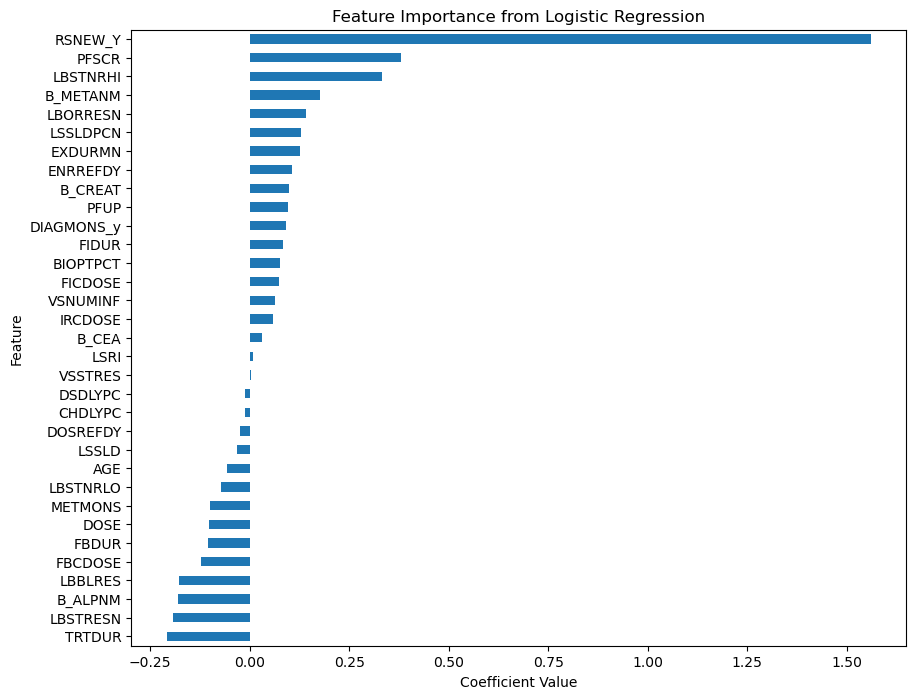

In [55]:
feature_importance.sort_values().plot(kind='barh', figsize=(10, 8))
plt.title('Feature Importance from Logistic Regression')
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
plt.show()

# XGBOOST Regression

In [57]:
import xgboost as xgb

result1= result1.drop(columns=['Predicted_New_Lesions'])

In [59]:
features = result1[['DOSREFDY','LSSLD','LSSLDPCN','RSNEW_Y','ENRREFDY','B_ALPNM','LBSTRESN','B_CEA','LBORRESN','PFUP','LBSTNRHI',
       'EXDURMN','METMONS','DOSE','DIAGMONS_y','VSSTRES','LBSTNRLO','LBBLRES','B_CREAT','BIOPTPCT','FBCDOSE','FICDOSE','IRCDOSE','AGE','FBDUR','VSNUMINF',
       'FIDUR','TRTDUR','LSRI','CHDLYPC','DSDLYPC','B_METANM','PFSCR']]
target = result1['LSNEWANY']

In [60]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

In [61]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, target, test_size=0.2, random_state=42)

In [62]:
# Initialize and fit the XGBoost model
model12 = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss')
model12.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, random_state=None, ...)

In [63]:
y_pred = model12.predict(X_test)

In [64]:
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

In [65]:
print(f"Accuracy: {accuracy:.4f}")
print("Confusion Matrix:")
print(conf_matrix)
print("Classification Report:")
print(class_report)

Accuracy: 0.3000
Confusion Matrix:
[[17 26]
 [16  1]]
Classification Report:
              precision    recall  f1-score   support

           0       0.52      0.40      0.45        43
           1       0.04      0.06      0.05        17

    accuracy                           0.30        60
   macro avg       0.28      0.23      0.25        60
weighted avg       0.38      0.30      0.33        60



In [66]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

y_train_pred = model12.predict(X_train_scaled)

y_test_pred = model12.predict(X_test_scaled)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

if train_accuracy > test_accuracy:
    print("\nPotential Overfitting Detected!")
else:
    print("\nNo Overfitting Detected!")

Training Accuracy: 0.7708
Test Accuracy: 0.3167

Potential Overfitting Detected!


# Feature Importance XGBoost Regression Model

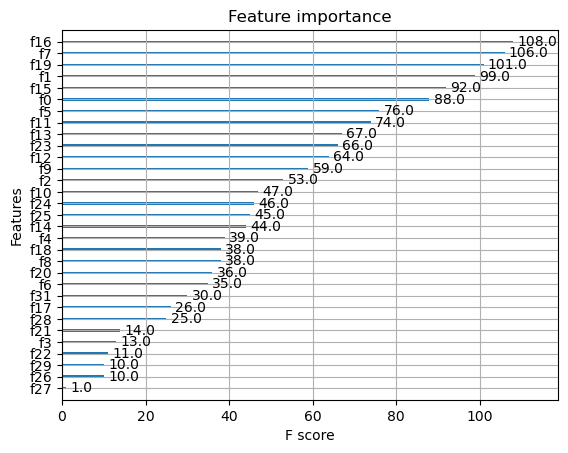

In [76]:
import xgboost as xgb
from xgboost import plot_importance
import matplotlib.pyplot as plt

plot_importance(model12)
plt.show()


# Hyperparameter 

In [78]:
result1.shape

(300, 37)

In [80]:
X = result1[['DOSREFDY','LSSLD','LSSLDPCN','RSNEW_Y','ENRREFDY','B_ALPNM','LBSTRESN','B_CEA','LBORRESN','PFUP','LBSTNRHI',
       'EXDURMN','METMONS','DOSE','DIAGMONS_y','VSSTRES','LBSTNRLO','LBBLRES','B_CREAT','BIOPTPCT','FBCDOSE','FICDOSE','IRCDOSE','AGE','FBDUR','VSNUMINF',
       'FIDUR','TRTDUR','LSRI','CHDLYPC','DSDLYPC','B_METANM','PFSCR']]
y = result1['LSNEWANY']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [82]:
y

2       0
3       1
8       0
12      0
13      1
       ..
1345    0
1348    0
1360    0
1362    0
1363    1
Name: LSNEWANY, Length: 300, dtype: int8

In [84]:
result1.shape

(300, 37)

In [86]:
result1.head()

,Unnamed: 0,SUBJID,LSNEWANY,DOSREFDY,LSSLD,LSSLDPCN,RSNEW_Y,ENRREFDY,B_ALPNM,LBSTRESN,...,FBDUR,VSNUMINF,FIDUR,TRTDUR,LSRI,CHDLYPC,DSDLYPC,B_METANM,PFSCR,study_month
2,5,201001002,0,25.050000,195.653846,27.785714,1,31.050000,173.0,64.343600,...,71.0,2.150000,71.0,60.0,4.0,0.00,0.00,3.0,1.0,month1
3,7,201001002,1,25.050000,195.653846,27.785714,1,31.050000,173.0,64.343600,...,71.0,2.150000,71.0,60.0,4.0,0.00,0.00,3.0,1.0,month1
8,19,201001007,0,14.148148,249.000000,10.777778,1,15.148148,261.0,75.239571,...,63.0,1.647059,63.0,52.0,4.0,0.25,0.25,4.0,1.0,month1
12,28,201001011,0,21.212121,59.700000,9.923077,1,35.212121,194.0,58.336411,...,70.0,1.647059,70.0,59.0,4.0,0.25,0.25,4.0,1.0,month1
13,30,201001011,1,21.212121,59.700000,9.923077,1,35.212121,194.0,58.336411,...,70.0,1.647059,70.0,59.0,4.0,0.25,0.25,4.0,1.0,month1


In [88]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
model13 = LogisticRegression(solver='liblinear')

In [90]:
param_grid = {
    'C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],  # Regularization parameter
    'penalty': ['l1', 'l2']  # Penalty term ('l1' for Lasso, 'l2' for Ridge)
}

In [92]:
grid_search = GridSearchCV(estimator=model13, param_grid=param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train_scaled, y_train)

best_model = grid_search.best_estimator_

In [93]:
best_model.fit(X_train_scaled, y_train)

LogisticRegression(C=0.001, penalty='l1', solver='liblinear')

In [94]:
y_test_pred = best_model.predict(X_test_scaled)

test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"Test Accuracy: {test_accuracy:.4f}")

print("\nConfusion Matrix on Test Data:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report on Test Data:")
print(classification_report(y_test, y_test_pred))

Test Accuracy: 0.7167

Confusion Matrix on Test Data:
[[43  0]
 [17  0]]

Classification Report on Test Data:
              precision    recall  f1-score   support

           0       0.72      1.00      0.83        43
           1       0.00      0.00      0.00        17

    accuracy                           0.72        60
   macro avg       0.36      0.50      0.42        60
weighted avg       0.51      0.72      0.60        60



# Feature Importance

Top 10 Most Important Features:
     Feature  Coefficient  Importance
0   DOSREFDY          0.0         0.0
17   LBBLRES          0.0         0.0
31  B_METANM          0.0         0.0
30   DSDLYPC          0.0         0.0
29   CHDLYPC          0.0         0.0
28      LSRI          0.0         0.0
27    TRTDUR          0.0         0.0
26     FIDUR          0.0         0.0
25  VSNUMINF          0.0         0.0
24     FBDUR          0.0         0.0


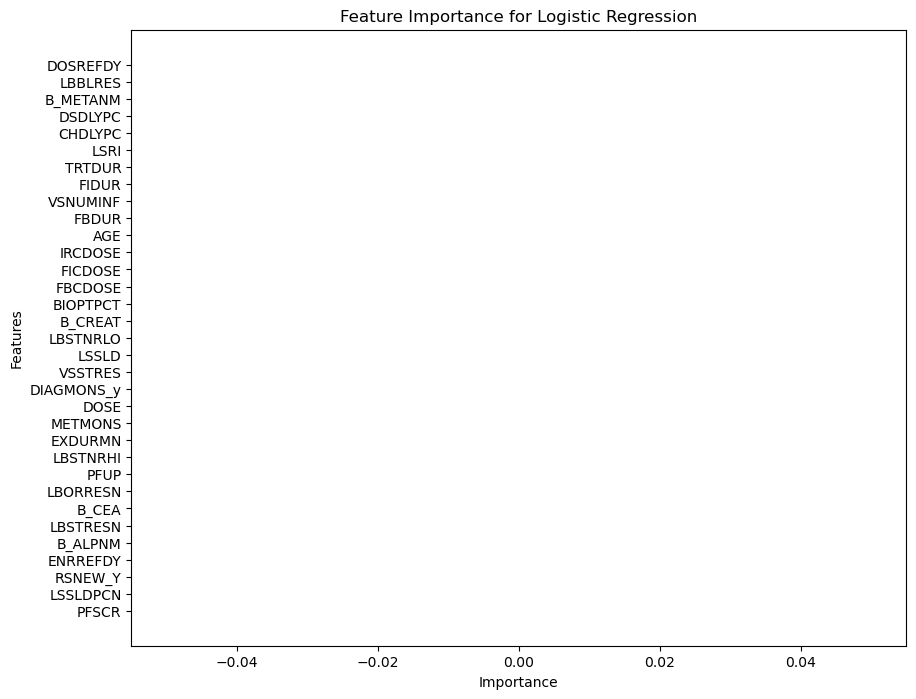

In [99]:
coefficients = best_model.coef_[0]  

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': coefficients
})

feature_importance['Importance'] = np.abs(feature_importance['Coefficient'])

# Sort features by importance
feature_importance = feature_importance.sort_values(by='Importance', ascending=False)

print("Top 10 Most Important Features:")
print(feature_importance.head(10))

plt.figure(figsize=(10, 8))
plt.barh(feature_importance['Feature'], feature_importance['Importance'], color='skyblue')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.title('Feature Importance for Logistic Regression')
plt.gca().invert_yaxis()
plt.show()


# Save in new file

In [101]:
predictions_df = pd.DataFrame({
    'SUBJID': result1.loc[X_test.index, 'SUBJID'],  # Extract SUBJID from original dataset using .loc
    'LSSLD_Change_Month1': y_test.values,
    'Predicted_New_LSSLD_Change_month1': y_test_pred
})

In [103]:
y_test_pred = best_model.predict(X_train_scaled)

predictions_df1 = pd.DataFrame({
    'SUBJID': result1.loc[X_train.index, 'SUBJID'],  # Extract SUBJID from original dataset using .loc
    'LSSLD_Change_Month1': y_train.values,
    'Predicted_New_LSSLD_Change_month1': y_train_pred
})

In [105]:
predictions=pd.concat([predictions_df,predictions_df1])

In [107]:
predictions.head()

,SUBJID,LSSLD_Change_Month1,Predicted_New_LSSLD_Change_month1
816,203402005,0,0
1132,203701008,0,0
574,201715001,0,0
43,201005011,0,0
959,203513005,0,0


In [109]:
predictions.shape

(300, 3)

pip install eli5

# Removing Overfitting by Elastic Net

In [111]:
X = result1[['DOSREFDY','LSSLD','LSSLDPCN','RSNEW_Y','ENRREFDY','B_ALPNM','LBSTRESN','B_CEA','LBORRESN','PFUP','LBSTNRHI',
       'EXDURMN','METMONS','DOSE','DIAGMONS_y','VSSTRES','LBSTNRLO','LBBLRES','B_CREAT','BIOPTPCT','FBCDOSE','FICDOSE','IRCDOSE','AGE','FBDUR','VSNUMINF',
       'FIDUR','TRTDUR','LSRI','CHDLYPC','DSDLYPC','B_METANM','PFSCR']]
y = result1['LSNEWANY']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
param_grid = {
    'penalty': ['elasticnet'],
    'solver': ['saga'],
    'l1_ratio': [0.1, 0.5, 0.7, 0.9],  
    'C': [0.1, 1.0, 10.0]  
}

In [113]:
model14 = GridSearchCV(LogisticRegression(max_iter=1000), param_grid, cv=10, scoring='accuracy')

In [115]:
model14.fit(X_train_scaled, y_train)

GridSearchCV(cv=10, estimator=LogisticRegression(max_iter=1000),
             param_grid={'C': [0.1, 1.0, 10.0],
                         'l1_ratio': [0.1, 0.5, 0.7, 0.9],
                         'penalty': ['elasticnet'], 'solver': ['saga']},
             scoring='accuracy')

In [116]:
best_model = model14.best_estimator_
y_train_pred = best_model.predict(X_train_scaled)
y_test_pred = best_model.predict(X_test_scaled)

In [117]:
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

if train_accuracy > test_accuracy:
    print("\nPotential Overfitting Detected!")
else:
    print("\nNo Overfitting Detected!")

Training Accuracy: 0.6833
Test Accuracy: 0.7000

No Overfitting Detected!


In [118]:
print("\nBest Parameters:")
print(model14.best_params_)


Best Parameters:
{'C': 0.1, 'l1_ratio': 0.5, 'penalty': 'elasticnet', 'solver': 'saga'}


In [119]:
cv_scores = cross_val_score(best_model, X_train_scaled, y_train, cv=5)
print(f"\nCross-validation scores: {cv_scores}")
print(f"Mean CV accuracy: {np.mean(cv_scores):.4f} (+/- {np.std(cv_scores):.4f})")


Cross-validation scores: [0.6875     0.6875     0.6875     0.66666667 0.66666667]
Mean CV accuracy: 0.6792 (+/- 0.0102)


In [120]:
print("\nClassification Report on Test Data:")
print(classification_report(y_test, y_test_pred))

print("\nConfusion Matrix on Test Data:")
print(confusion_matrix(y_test, y_test_pred))


Classification Report on Test Data:
              precision    recall  f1-score   support

           0       0.71      0.98      0.82        43
           1       0.00      0.00      0.00        17

    accuracy                           0.70        60
   macro avg       0.36      0.49      0.41        60
weighted avg       0.51      0.70      0.59        60


Confusion Matrix on Test Data:
[[42  1]
 [17  0]]


# Feature Importance

In [127]:
# Feature Importance (Coefficients)
feature_importance = best_model.coef_[0]
features = X.columns
feature_importance_df = pd.DataFrame({'Feature': features, 'Importance': feature_importance})

# Displaying feature importance
print("\nFeature Importance:")
print(feature_importance_df.sort_values(by='Importance', ascending=False))


Feature Importance:
       Feature  Importance
3      RSNEW_Y    0.832702
31    B_METANM    0.061190
10    LBSTNRHI    0.053116
2     LSSLDPCN    0.045132
19    BIOPTPCT    0.023302
14  DIAGMONS_y    0.000861
0     DOSREFDY    0.000000
24       FBDUR    0.000000
21     FICDOSE    0.000000
22     IRCDOSE    0.000000
23         AGE    0.000000
26       FIDUR    0.000000
25    VSNUMINF    0.000000
27      TRTDUR    0.000000
28        LSRI    0.000000
29     CHDLYPC    0.000000
30     DSDLYPC    0.000000
20     FBCDOSE    0.000000
16    LBSTNRLO    0.000000
18     B_CREAT    0.000000
1        LSSLD    0.000000
15     VSSTRES    0.000000
13        DOSE    0.000000
12     METMONS    0.000000
11     EXDURMN    0.000000
9         PFUP    0.000000
8     LBORRESN    0.000000
7        B_CEA    0.000000
4     ENRREFDY    0.000000
32       PFSCR    0.000000
6     LBSTRESN   -0.027147
17     LBBLRES   -0.051269
5      B_ALPNM   -0.060440


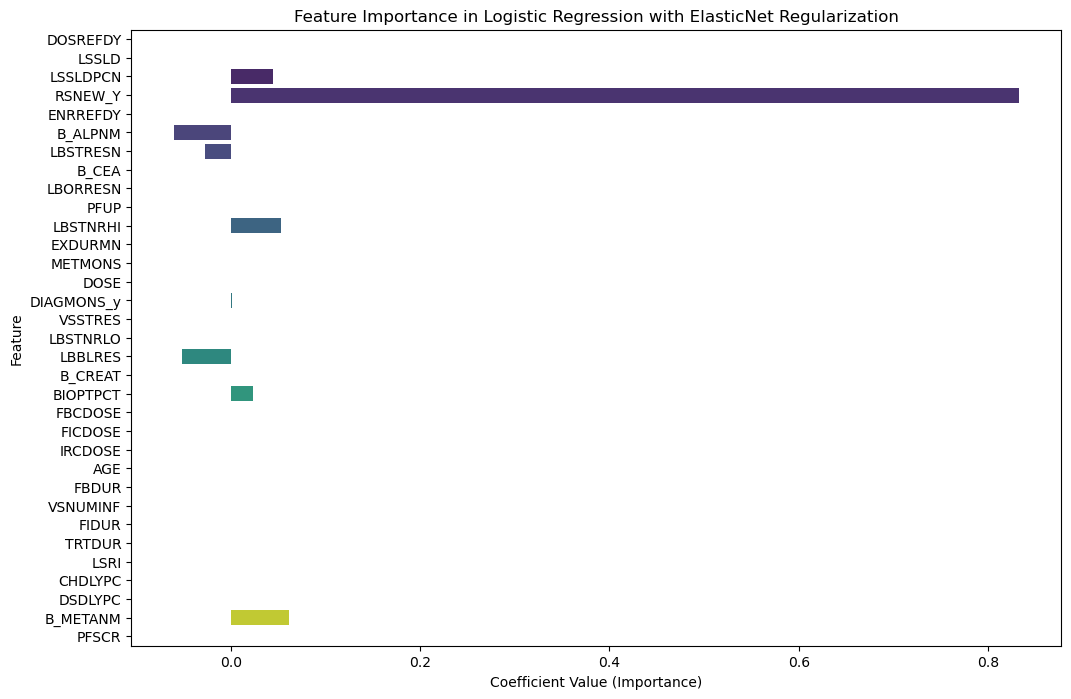

In [132]:
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette="viridis")
plt.title('Feature Importance in Logistic Regression with ElasticNet Regularization')
plt.xlabel('Coefficient Value (Importance)')
plt.ylabel('Feature')
plt.show()

# Regression with Linear,Decision Tree,Random Forest,Gadient Boosting,Support Vector and Neural Network

In [ ]:

features = result1[['DOSREFDY', 'LSSLD', 'LSSLDPCN', 'RSNEW_Y', 'ENRREFDY', 'B_ALPNM', 'LBSTRESN', 'B_CEA',
                    'LBORRESN', 'PFUP', 'LBSTNRHI', 'EXDURMN', 'METMONS', 'DOSE', 'DIAGMONS_y', 'VSSTRES', 'LBSTNRLO',
                    'LBBLRES', 'B_CREAT', 'BIOPTPCT', 'FBCDOSE', 'FICDOSE', 'IRCDOSE', 'AGE', 'FBDUR', 'VSNUMINF',
                    'FIDUR', 'TRTDUR', 'LSRI', 'CHDLYPC', 'DSDLYPC', 'B_METANM', 'PFSCR']]
target = result1['LSNEWANY']

X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest": RandomForestRegressor(),
    "Gradient Boosting": GradientBoostingRegressor(),
    "Support Vector Regression": make_pipeline(StandardScaler(), SVR()),
    "Neural Network": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=1000))
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    # Calculate Mean Squared Error and R² Score
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    print(f"{name} - Mean Squared Error: {mse}, R² Score: {r2}")
